1. Kütüphaneler ve çalışma ortamı

In [1]:
# Temel kütüphaneler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import warnings

from concurrent.futures import ThreadPoolExecutor, as_completed
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

print("Çalışma ortamı hazır.")

Çalışma ortamı hazır.


2. Hücre – NOAA iklim verilerini indirme.

In [2]:
# NOAA veri kaynakları
GW_URL = "https://psl.noaa.gov/data/correlation/gmsst.data"
IPO_URL = "https://psl.noaa.gov/data/timeseries/IPOTPI/tpi.timeseries.ersstv5.data"

gw_response = requests.get(GW_URL)
ipo_response = requests.get(IPO_URL)

gw_response.raise_for_status()
ipo_response.raise_for_status()

print("GW verisi indirildi:", len(gw_response.text))
print("IPO verisi indirildi:", len(ipo_response.text))

GW verisi indirildi: 8219
IPO verisi indirildi: 22088


3. Hücre – Aylık iklim verilerini hazırlama

In [3]:
def parse_noaa_data(raw_text, column_name):
    records = []

    for line in raw_text.splitlines():
        parts = line.split()

        if len(parts) != 13:
            continue

        try:
            year = int(parts[0])
            values = [float(value) for value in parts[1:]]

            for month, value in enumerate(values, start=1):
                if value < 9000:
                    records.append({
                        "DATE": pd.Timestamp(year, month, 1),
                        column_name: value
                    })
        except ValueError:
            continue

    return pd.DataFrame(records)


gw_df = parse_noaa_data(gw_response.text, "GW")
ipo_df = parse_noaa_data(ipo_response.text, "IPO")

climate_monthly = pd.merge(
    gw_df, ipo_df, on="DATE", how="inner"
)

climate_monthly = climate_monthly[
    climate_monthly["DATE"].between(
        "1959-12-01", "2023-12-01"
    )
].reset_index(drop=True)

print("İklim veri boyutu:", climate_monthly.shape)
print("Eksik değerler:\n", climate_monthly.isna().sum())

display(climate_monthly.head())
display(climate_monthly.tail())

İklim veri boyutu: (769, 3)
Eksik değerler:
 DATE    0
GW      0
IPO     0
dtype: int64


,DATE,GW,IPO
0,1959-12-01,0.10,-0.191
1,1960-01-01,0.05,-0.084
2,1960-02-01,0.24,-0.155
3,1960-03-01,-0.51,0.021
4,1960-04-01,-0.24,0.127


,DATE,GW,IPO
764,2023-08-01,1.41,0.311
765,2023-09-01,1.86,0.352
766,2023-10-01,1.56,0.563
767,2023-11-01,1.63,0.725
768,2023-12-01,1.61,0.553


4. Hücre – İstasyon listesini indirme

In [4]:
stations_url = "https://www.ncei.noaa.gov/pub/data/ghcn/daily/ghcnd-stations.txt"

stations = pd.read_fwf(
    stations_url,
    colspecs=[
        (0, 11), (12, 20), (21, 30),
        (31, 37), (38, 40), (41, 71)
    ],
    names=[
        "STATION", "LATITUDE", "LONGITUDE",
        "ELEVATION", "STATE", "NAME"
    ]
)

ohio_stations = (
    stations[stations["STATE"] == "OH"]
    .dropna(subset=["STATION"])
    .copy()
)

print("Ohio istasyon sayısı:", len(ohio_stations))
display(ohio_stations.head())

Ohio istasyon sayısı: 1545


,STATION,LATITUDE,LONGITUDE,ELEVATION,STATE,NAME
87649,US1OHAB0002,41.8921,-80.8244,191.1,OH,ASHTABULA 1.6 WNW
87650,US1OHAB0004,41.8757,-80.7567,210.6,OH,ASHTABULA 2.1 E
87651,US1OHAB0008,41.7511,-80.5834,301.1,OH,PIERPONT 0.8 W
87652,US1OHAB0015,41.8774,-80.7685,200.9,OH,ASHTABULA 1.5 E
87653,US1OHAB0016,41.7400,-80.5944,301.1,OH,PIERPONT 1.5 WSW


5. Hücre – GSOM istasyonlarını belirleme

In [5]:
from bs4 import BeautifulSoup

gsom_url = "https://www.ncei.noaa.gov/data/gsom/access/"

response = requests.get(gsom_url)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

gsom_station_ids = {
    link.get("href").removesuffix(".csv")
    for link in soup.find_all("a")
    if link.get("href", "").endswith(".csv")
}

available_stations = ohio_stations[
    ohio_stations["STATION"].isin(gsom_station_ids)
].copy()

print("GSOM'da bulunan Ohio istasyonu:", len(available_stations))
display(available_stations.head())

GSOM'da bulunan Ohio istasyonu: 1488


,STATION,LATITUDE,LONGITUDE,ELEVATION,STATE,NAME
87649,US1OHAB0002,41.8921,-80.8244,191.1,OH,ASHTABULA 1.6 WNW
87650,US1OHAB0004,41.8757,-80.7567,210.6,OH,ASHTABULA 2.1 E
87651,US1OHAB0008,41.7511,-80.5834,301.1,OH,PIERPONT 0.8 W
87652,US1OHAB0015,41.8774,-80.7685,200.9,OH,ASHTABULA 1.5 E
87653,US1OHAB0016,41.7400,-80.5944,301.1,OH,PIERPONT 1.5 WSW


6. Hücre – Yağış verilerini indirme ve %95 koşulunu uygulama

In [6]:
def download_station(station_id):
    url = f"https://www.ncei.noaa.gov/data/gsom/access/{station_id}.csv"

    try:
        df = pd.read_csv(url)

        df["DATE"] = pd.to_datetime(df["DATE"])
        df["PRCP"] = pd.to_numeric(df["PRCP"], errors="coerce")

        period = df[
            df["DATE"].between("1960-01-01", "2023-12-31")
        ]

        if period["PRCP"].notna().sum() / 768 >= 0.95:
            return df[
                df["DATE"].between("1959-12-01", "2023-12-31")
            ][["STATION", "DATE", "PRCP"]]

    except Exception:
        return None

    return None


station_ids = available_stations["STATION"].tolist()
results = []

with ThreadPoolExecutor(max_workers=10) as executor:
    futures = [executor.submit(download_station, sid) for sid in station_ids]

    for i, future in enumerate(as_completed(futures), 1):
        result = future.result()

        if result is not None:
            results.append(result)

        if i % 200 == 0:
            print(f"{i}/{len(station_ids)} istasyon kontrol edildi.")

precip_monthly = pd.concat(results, ignore_index=True)

print("Seçilen istasyon:", precip_monthly["STATION"].nunique())
print("Toplam aylık kayıt:", len(precip_monthly))

200/1488 istasyon kontrol edildi.
400/1488 istasyon kontrol edildi.
600/1488 istasyon kontrol edildi.
800/1488 istasyon kontrol edildi.
1000/1488 istasyon kontrol edildi.
1200/1488 istasyon kontrol edildi.
1400/1488 istasyon kontrol edildi.
Seçilen istasyon: 59
Toplam aylık kayıt: 45012


7. Hücre – Kış yağış ortalaması

In [10]:
winter_precip = (
    winter_data.groupby(["STATION", "WINTER_YEAR"])["PRCP"]
    .agg(["mean", "count"])
    .reset_index()
)

winter_precip = winter_precip[
    winter_precip["count"] == 3
].rename(columns={"mean": "PRECIPITATION"})

winter_precip = winter_precip[
    ["STATION", "WINTER_YEAR", "PRECIPITATION"]
]

model_data = winter_precip.merge(
    winter_climate,
    on="WINTER_YEAR",
    how="inner"
).sort_values(
    ["STATION", "WINTER_YEAR"]
).reset_index(drop=True)

print("Veri boyutu:", model_data.shape)
print("İstasyon:", model_data["STATION"].nunique())
print("Kış yılı:", model_data["WINTER_YEAR"].nunique())

display(model_data.head())

Veri boyutu: (3655, 5)
İstasyon: 59
Kış yılı: 64


,STATION,WINTER_YEAR,PRECIPITATION,GW,IPO
0,USC00330279,1960,84.900000,0.130000,-0.143333
1,USC00330279,1961,54.733333,0.160000,0.112667
2,USC00330279,1962,90.933333,0.013333,-0.627333
3,USC00330279,1963,48.666667,0.070000,-0.450000
4,USC00330279,1964,54.733333,-0.073333,0.461000


8. Hücre – Küresel ısınma (GW) ve okyanus salınımı (IPO) değerlerinin ortalaması

In [8]:
climate_monthly["YEAR"] = climate_monthly["DATE"].dt.year
climate_monthly["MONTH"] = climate_monthly["DATE"].dt.month

climate_monthly["WINTER_YEAR"] = np.where(
    climate_monthly["MONTH"] == 12,
    climate_monthly["YEAR"] + 1,
    climate_monthly["YEAR"]
)

winter_climate = (
    climate_monthly[
        climate_monthly["MONTH"].isin([12, 1, 2]) &
        climate_monthly["WINTER_YEAR"].between(1960, 2023)
    ]
    .groupby("WINTER_YEAR")[["GW", "IPO"]]
    .mean()
    .reset_index()
)

print("İklim verisi:", winter_climate.shape)
print("Eksik değer:", winter_climate.isna().sum().sum())

display(winter_climate.head())

İklim verisi: (64, 3)
Eksik değer: 0


,WINTER_YEAR,GW,IPO
0,1960,0.130000,-0.143333
1,1961,0.160000,0.112667
2,1962,0.013333,-0.627333
3,1963,0.070000,-0.450000
4,1964,-0.073333,0.461000


9. Hücre – Analiz veri setini oluşturma

In [9]:
model_data = winter_precip.merge(
    winter_climate,
    on="WINTER_YEAR",
    how="inner"
)

model_data = model_data.sort_values(
    ["STATION", "WINTER_YEAR"]
).reset_index(drop=True)

print("Veri boyutu:", model_data.shape)
print("İstasyon:", model_data["STATION"].nunique())
print("Kış yılı:", model_data["WINTER_YEAR"].nunique())
print("Eksik değer:", model_data.isna().sum().sum())

display(model_data.head())

Veri boyutu: (3655, 5)
İstasyon: 59
Kış yılı: 64
Eksik değer: 0


,STATION,WINTER_YEAR,PRECIPITATION,GW,IPO
0,USC00330279,1960,254.7,0.130000,-0.143333
1,USC00330279,1961,164.2,0.160000,0.112667
2,USC00330279,1962,272.8,0.013333,-0.627333
3,USC00330279,1963,146.0,0.070000,-0.450000
4,USC00330279,1964,164.2,-0.073333,0.461000


10. Hücre – İstasyon başına gözlem sayısını kontrol

In [11]:
station_counts = (
    model_data.groupby("STATION")["WINTER_YEAR"]
    .agg(["count", "min", "max"])
    .reset_index()
)

print("İstasyon sayısı:", len(station_counts))
print("En az gözlem:", station_counts["count"].min())
print("En fazla gözlem:", station_counts["count"].max())

display(station_counts)

İstasyon sayısı: 59
En az gözlem: 49
En fazla gözlem: 64


,STATION,count,min,max
0,USC00330279,60,1960,2023
1,USC00330563,63,1960,2023
2,USC00330862,64,1960,2023
3,USC00331057,59,1960,2023
4,USC00331072,64,1960,2023
5,USC00331390,62,1960,2023
6,USC00331458,62,1960,2023
7,USC00331592,62,1960,2023
8,USC00331890,63,1960,2023
9,USC00332067,60,1960,2023


11. Hücre – XGBoost kütüphanesini hazırlama

In [12]:
import xgboost as xgb

from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV, train_test_split

print("XGBoost sürümü:", xgb.__version__)
print("XGBoost hazır.")

XGBoost sürümü: 3.4.1
XGBoost hazır.


12. Hücre – İstasyon bazında XGBoost optimizasyonu

In [14]:
FEATURES = ["GW", "IPO"]
TARGET = "PRECIPITATION"

param_grid = {
    "learning_rate": [0.01, 0.1, 0.3],
    "max_depth": [3, 6, 10],
    "n_estimators": [50, 100, 200],
    "subsample": [0.5, 1.0]
}

station_models = {}
xgb_results = []

for station in model_data["STATION"].unique():

    station_data = model_data[
        model_data["STATION"] == station
    ]

    X_station = station_data[FEATURES]
    y_station = station_data[TARGET]

    X_train, X_val, y_train, y_val = train_test_split(
        X_station,
        y_station,
        test_size=0.20,
        random_state=SEED
    )

    xgb_model = XGBRegressor(
        objective="reg:squarederror",
        random_state=SEED,
        n_jobs=1
    )

    grid_search = GridSearchCV(
        estimator=xgb_model,
        param_grid=param_grid,
        scoring="neg_mean_squared_error",
        cv=5,
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    predictions = best_model.predict(X_val)

    station_models[station] = best_model

    xgb_results.append({
        "STATION": station,
        "BEST_PARAMS": grid_search.best_params_,
        "VALIDATION_MSE": mean_squared_error(y_val, predictions),
        "VALIDATION_R2": r2_score(y_val, predictions)
    })

    print(f"{station} tamamlandı.")

xgb_results = pd.DataFrame(xgb_results)

print("\nOptimizasyon tamamlandı.")
display(xgb_results.head())

USC00330279 tamamlandı.
USC00330563 tamamlandı.
USC00330862 tamamlandı.
USC00331057 tamamlandı.
USC00331072 tamamlandı.
USC00331390 tamamlandı.
USC00331458 tamamlandı.
USC00331592 tamamlandı.
USC00331890 tamamlandı.
USC00332067 tamamlandı.
USC00332098 tamamlandı.
USC00332485 tamamlandı.
USC00332791 tamamlandı.
USC00332928 tamamlandı.
USC00332974 tamamlandı.
USC00333021 tamamlandı.
USC00333029 tamamlandı.
USC00333375 tamamlandı.
USC00333758 tamamlandı.
USC00333780 tamamlandı.
USC00333915 tamamlandı.
USC00334434 tamamlandı.
USC00334551 tamamlandı.
USC00334979 tamamlandı.
USC00335505 tamamlandı.
USC00335718 tamamlandı.
USC00335747 tamamlandı.
USC00335786 tamamlandı.
USC00335857 tamamlandı.
USC00336118 tamamlandı.
USC00336196 tamamlandı.
USC00336389 tamamlandı.
USC00336405 tamamlandı.
USC00336465 tamamlandı.
USC00336630 tamamlandı.
USC00336697 tamamlandı.
USC00336781 tamamlandı.
USC00336949 tamamlandı.
USC00337255 tamamlandı.
USC00337693 tamamlandı.
USC00338552 tamamlandı.
USC00338609 tama

,STATION,BEST_PARAMS,VALIDATION_MSE,VALIDATION_R2
0,USC00330279,"{'learning_rate': 0.01, 'max_depth': 3, 'n_est...",304.416920,-0.290660
1,USC00330563,"{'learning_rate': 0.01, 'max_depth': 3, 'n_est...",271.114120,-0.234479
2,USC00330862,"{'learning_rate': 0.01, 'max_depth': 3, 'n_est...",277.499357,-0.480884
3,USC00331057,"{'learning_rate': 0.01, 'max_depth': 3, 'n_est...",397.333065,-0.072479
4,USC00331072,"{'learning_rate': 0.01, 'max_depth': 3, 'n_est...",144.257041,-0.185282


13. Hücre – XGBoost Gain önem değerleri

In [15]:
gain_results = []

for station, model in station_models.items():

    importance = model.get_booster().get_score(
        importance_type="gain"
    )

    gw_gain = importance.get("GW", 0)
    ipo_gain = importance.get("IPO", 0)

    total_gain = gw_gain + ipo_gain

    if total_gain > 0:
        gw_percent = gw_gain / total_gain * 100
        ipo_percent = ipo_gain / total_gain * 100
    else:
        gw_percent = 0
        ipo_percent = 0

    gain_results.append({
        "STATION": station,
        "GW_GAIN": gw_percent,
        "IPO_GAIN": ipo_percent
    })

gain_results = pd.DataFrame(gain_results)

print("Gain analizi tamamlandı.")
display(gain_results.head())

Gain analizi tamamlandı.


,STATION,GW_GAIN,IPO_GAIN
0,USC00330279,48.186753,51.813247
1,USC00330563,51.510182,48.489818
2,USC00330862,58.225800,41.774200
3,USC00331057,45.966394,54.033606
4,USC00331072,52.841396,47.158604


14. Hücre – Tam veriyle modelleme ve PDP analizi

In [16]:
from sklearn.base import clone
from sklearn.inspection import partial_dependence

station_full_models = {}
gain_results = []
pdp_results = []

for station in model_data["STATION"].unique():

    station_data = model_data[
        model_data["STATION"] == station
    ]

    X_station = station_data[FEATURES]
    y_station = station_data[TARGET]

    # En iyi parametrelerle tüm veri üzerinde yeniden eğitim
    full_model = clone(
        station_models[station]
    )

    full_model.fit(X_station, y_station)
    station_full_models[station] = full_model

    # Gain önemleri: toplam kazanç
    gain = full_model.get_booster().get_score(
        importance_type="total_gain"
    )

    gw_gain = gain.get("GW", 0)
    ipo_gain = gain.get("IPO", 0)
    total_gain = gw_gain + ipo_gain

    if total_gain > 0:
        gw_gain_pct = gw_gain / total_gain * 100
        ipo_gain_pct = ipo_gain / total_gain * 100
    else:
        gw_gain_pct = 0
        ipo_gain_pct = 0

    gain_results.append({
        "STATION": station,
        "GW_GAIN": gw_gain_pct,
        "IPO_GAIN": ipo_gain_pct
    })

    # PDP önemleri: marjinal tahminlerin varyansı
    pdp_importance = {}

    for feature in FEATURES:

        pdp = partial_dependence(
            full_model,
            X_station,
            features=[feature],
            grid_resolution=50
        )

        pdp_values = pdp["average"].ravel()
        pdp_importance[feature] = np.var(pdp_values)

    total_pdp = sum(pdp_importance.values())

    pdp_results.append({
        "STATION": station,
        "GW_PDP": pdp_importance["GW"] / total_pdp * 100
        if total_pdp > 0 else 0,
        "IPO_PDP": pdp_importance["IPO"] / total_pdp * 100
        if total_pdp > 0 else 0
    })

    print(f"{station} tamamlandı.")

gain_results = pd.DataFrame(gain_results)
pdp_results = pd.DataFrame(pdp_results)

print("\nTam veriyle Gain ve PDP analizleri tamamlandı.")

display(gain_results.head())
display(pdp_results.head())

USC00330279 tamamlandı.
USC00330563 tamamlandı.
USC00330862 tamamlandı.
USC00331057 tamamlandı.
USC00331072 tamamlandı.
USC00331390 tamamlandı.
USC00331458 tamamlandı.
USC00331592 tamamlandı.
USC00331890 tamamlandı.
USC00332067 tamamlandı.
USC00332098 tamamlandı.
USC00332485 tamamlandı.
USC00332791 tamamlandı.
USC00332928 tamamlandı.
USC00332974 tamamlandı.
USC00333021 tamamlandı.
USC00333029 tamamlandı.
USC00333375 tamamlandı.
USC00333758 tamamlandı.
USC00333780 tamamlandı.
USC00333915 tamamlandı.
USC00334434 tamamlandı.
USC00334551 tamamlandı.
USC00334979 tamamlandı.
USC00335505 tamamlandı.
USC00335718 tamamlandı.
USC00335747 tamamlandı.
USC00335786 tamamlandı.
USC00335857 tamamlandı.
USC00336118 tamamlandı.
USC00336196 tamamlandı.
USC00336389 tamamlandı.
USC00336405 tamamlandı.
USC00336465 tamamlandı.
USC00336630 tamamlandı.
USC00336697 tamamlandı.
USC00336781 tamamlandı.
USC00336949 tamamlandı.
USC00337255 tamamlandı.
USC00337693 tamamlandı.
USC00338552 tamamlandı.
USC00338609 tama

,STATION,GW_GAIN,IPO_GAIN
0,USC00330279,57.871869,42.128131
1,USC00330563,60.154826,39.845174
2,USC00330862,54.960050,45.039950
3,USC00331057,62.089555,37.910445
4,USC00331072,38.467215,61.532785


,STATION,GW_PDP,IPO_PDP
0,USC00330279,72.012253,27.987749
1,USC00330563,77.019905,22.980089
2,USC00330862,66.100433,33.899559
3,USC00331057,78.617393,21.382603
4,USC00331072,38.005100,61.994900


15. Hücre – XGBoost SHAP analizi

In [17]:
import shap

shap_values_by_station = {}
shap_results = []

for station, model in station_full_models.items():

    station_data = model_data[
        model_data["STATION"] == station
    ]

    X_station = station_data[FEATURES]

    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_station)

    shap_values_by_station[station] = shap_values

    importance = np.abs(shap_values).mean(axis=0)
    total_importance = importance.sum()

    if total_importance > 0:
        importance_pct = importance / total_importance * 100
    else:
        importance_pct = [0, 0]

    shap_results.append({
        "STATION": station,
        "GW_SHAP": importance_pct[0],
        "IPO_SHAP": importance_pct[1]
    })

    print(f"{station} tamamlandı.")

shap_results = pd.DataFrame(shap_results)

print("\nXGBoost SHAP analizi tamamlandı.")
display(shap_results.head())

USC00330279 tamamlandı.
USC00330563 tamamlandı.
USC00330862 tamamlandı.
USC00331057 tamamlandı.
USC00331072 tamamlandı.
USC00331390 tamamlandı.
USC00331458 tamamlandı.
USC00331592 tamamlandı.
USC00331890 tamamlandı.
USC00332067 tamamlandı.
USC00332098 tamamlandı.
USC00332485 tamamlandı.
USC00332791 tamamlandı.
USC00332928 tamamlandı.
USC00332974 tamamlandı.
USC00333021 tamamlandı.
USC00333029 tamamlandı.
USC00333375 tamamlandı.
USC00333758 tamamlandı.
USC00333780 tamamlandı.
USC00333915 tamamlandı.
USC00334434 tamamlandı.
USC00334551 tamamlandı.
USC00334979 tamamlandı.
USC00335505 tamamlandı.
USC00335718 tamamlandı.
USC00335747 tamamlandı.
USC00335786 tamamlandı.
USC00335857 tamamlandı.
USC00336118 tamamlandı.
USC00336196 tamamlandı.
USC00336389 tamamlandı.
USC00336405 tamamlandı.
USC00336465 tamamlandı.
USC00336630 tamamlandı.
USC00336697 tamamlandı.
USC00336781 tamamlandı.
USC00336949 tamamlandı.
USC00337255 tamamlandı.
USC00337693 tamamlandı.
USC00338552 tamamlandı.
USC00338609 tama

,STATION,GW_SHAP,IPO_SHAP
0,USC00330279,49.341949,50.658054
1,USC00330563,66.168045,33.831955
2,USC00330862,57.884861,42.115143
3,USC00331057,68.037613,31.962391
4,USC00331072,49.225296,50.774700


16. Hücre – FFNN kütüphanelerini hazırlama

In [20]:
!pip install -q keras-tuner

In [21]:
!pip install -q keras-tuner

import tensorflow as tf
import keras_tuner as kt

from tensorflow import keras
from sklearn.preprocessing import StandardScaler

print("TensorFlow:", tf.__version__)
print("Keras Tuner hazır.")

TensorFlow: 2.21.0
Keras Tuner hazır.


17. hücreyi oluşturma

In [24]:
from tensorflow import keras
from tensorflow.keras.callbacks import EarlyStopping

station_ffnn_models = {}
station_ffnn_background = {}
ffnn_results = []

for station in model_data["STATION"].unique():

    station_data = model_data[
        model_data["STATION"] == station
    ]

    X = station_data[FEATURES].values.astype("float32")
    y = station_data[TARGET].values.astype("float32")

    X_train, X_val, y_train, y_val = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=SEED
    )

    model = keras.Sequential([
        keras.layers.Input(shape=(2,)),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(1, activation="linear")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.01
        ),
        loss="mse"
    )

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=100,
        callbacks=[early_stopping],
        verbose=0
    )

    predictions = model.predict(
        X_val,
        verbose=0
    ).ravel()

    station_ffnn_models[station] = model
    station_ffnn_background[station] = X_train

    ffnn_results.append({
        "STATION": station,
        "VALIDATION_MSE": mean_squared_error(
            y_val, predictions
        ),
        "VALIDATION_R2": r2_score(
            y_val, predictions
        ),
        "EPOCHS": len(history.history["loss"])
    })

    print(f"{station} tamamlandı.")

ffnn_results = pd.DataFrame(ffnn_results)

print("\nFFNN eğitimi tamamlandı.")
display(ffnn_results.head())

USC00330279 tamamlandı.
USC00330563 tamamlandı.
USC00330862 tamamlandı.
USC00331057 tamamlandı.
USC00331072 tamamlandı.
USC00331390 tamamlandı.
USC00331458 tamamlandı.
USC00331592 tamamlandı.
USC00331890 tamamlandı.
USC00332067 tamamlandı.
USC00332098 tamamlandı.
USC00332485 tamamlandı.
USC00332791 tamamlandı.
USC00332928 tamamlandı.
USC00332974 tamamlandı.
USC00333021 tamamlandı.
USC00333029 tamamlandı.
USC00333375 tamamlandı.
USC00333758 tamamlandı.
USC00333780 tamamlandı.
USC00333915 tamamlandı.
USC00334434 tamamlandı.
USC00334551 tamamlandı.
USC00334979 tamamlandı.
USC00335505 tamamlandı.
USC00335718 tamamlandı.
USC00335747 tamamlandı.
USC00335786 tamamlandı.
USC00335857 tamamlandı.
USC00336118 tamamlandı.
USC00336196 tamamlandı.
USC00336389 tamamlandı.
USC00336405 tamamlandı.
USC00336465 tamamlandı.
USC00336630 tamamlandı.
USC00336697 tamamlandı.
USC00336781 tamamlandı.
USC00336949 tamamlandı.
USC00337255 tamamlandı.
USC00337693 tamamlandı.
USC00338552 tamamlandı.
USC00338609 tama

,STATION,VALIDATION_MSE,VALIDATION_R2,EPOCHS
0,USC00330279,562.156921,-1.383419,26
1,USC00330563,633.416626,-1.884172,30
2,USC00330862,653.121948,-2.485406,25
3,USC00331057,436.358856,-0.177818,36
4,USC00331072,500.467102,-3.112065,26


18. hücre – FFNN için SHAP analizi

In [25]:
ffnn_shap_values = {}
ffnn_shap_results = []

for station, model in station_ffnn_models.items():

    X_station = model_data[
        model_data["STATION"] == station
    ][FEATURES].values.astype("float32")

    background = station_ffnn_background[station]

    explainer = shap.GradientExplainer(
        model,
        background
    )

    shap_values = explainer.shap_values(X_station)

    shap_values = np.array(shap_values).squeeze()

    ffnn_shap_values[station] = shap_values

    importance = np.abs(shap_values).mean(axis=0)
    total_importance = importance.sum()

    if total_importance > 0:
        importance_pct = importance / total_importance * 100
    else:
        importance_pct = [0, 0]

    ffnn_shap_results.append({
        "STATION": station,
        "GW_SHAP": importance_pct[0],
        "IPO_SHAP": importance_pct[1]
    })

    print(f"{station} tamamlandı.")

ffnn_shap_results = pd.DataFrame(ffnn_shap_results)

print("\nFFNN SHAP analizi tamamlandı.")
display(ffnn_shap_results.head())

USC00330279 tamamlandı.
USC00330563 tamamlandı.
USC00330862 tamamlandı.
USC00331057 tamamlandı.
USC00331072 tamamlandı.
USC00331390 tamamlandı.
USC00331458 tamamlandı.
USC00331592 tamamlandı.
USC00331890 tamamlandı.
USC00332067 tamamlandı.
USC00332098 tamamlandı.
USC00332485 tamamlandı.
USC00332791 tamamlandı.
USC00332928 tamamlandı.
USC00332974 tamamlandı.
USC00333021 tamamlandı.
USC00333029 tamamlandı.
USC00333375 tamamlandı.
USC00333758 tamamlandı.
USC00333780 tamamlandı.
USC00333915 tamamlandı.
USC00334434 tamamlandı.
USC00334551 tamamlandı.
USC00334979 tamamlandı.
USC00335505 tamamlandı.
USC00335718 tamamlandı.
USC00335747 tamamlandı.
USC00335786 tamamlandı.
USC00335857 tamamlandı.
USC00336118 tamamlandı.
USC00336196 tamamlandı.
USC00336389 tamamlandı.
USC00336405 tamamlandı.
USC00336465 tamamlandı.
USC00336630 tamamlandı.
USC00336697 tamamlandı.
USC00336781 tamamlandı.
USC00336949 tamamlandı.
USC00337255 tamamlandı.
USC00337693 tamamlandı.
USC00338552 tamamlandı.
USC00338609 tama

,STATION,GW_SHAP,IPO_SHAP
0,USC00330279,66.135489,33.864511
1,USC00330563,69.899060,30.100940
2,USC00330862,75.920867,24.079133
3,USC00331057,79.073636,20.926364
4,USC00331072,58.468981,41.531019


19. hücre – SHAP sonuçlarını birleştirme

In [26]:
shap_comparison = (
    shap_results.merge(
        ffnn_shap_results,
        on="STATION",
        suffixes=("_XGBOOST", "_FFNN")
    )
)

shap_comparison["GW_SHAP_MEDIAN"] = shap_comparison[
    ["GW_SHAP_XGBOOST", "GW_SHAP_FFNN"]
].median(axis=1)

shap_comparison["IPO_SHAP_MEDIAN"] = shap_comparison[
    ["IPO_SHAP_XGBOOST", "IPO_SHAP_FFNN"]
].median(axis=1)

print("SHAP karşılaştırması tamamlandı.")
display(shap_comparison.head())

SHAP karşılaştırması tamamlandı.


,STATION,GW_SHAP_XGBOOST,IPO_SHAP_XGBOOST,GW_SHAP_FFNN,IPO_SHAP_FFNN,GW_SHAP_MEDIAN,IPO_SHAP_MEDIAN
0,USC00330279,49.341949,50.658054,66.135489,33.864511,57.738719,42.261283
1,USC00330563,66.168045,33.831955,69.899060,30.100940,68.033552,31.966448
2,USC00330862,57.884861,42.115143,75.920867,24.079133,66.902864,33.097138
3,USC00331057,68.037613,31.962391,79.073636,20.926364,73.555624,26.444377
4,USC00331072,49.225296,50.774700,58.468981,41.531019,53.847138,46.152860


XGBoost ve FFNN modellerinin genel SHAP önem karşılaştırmasıydı.

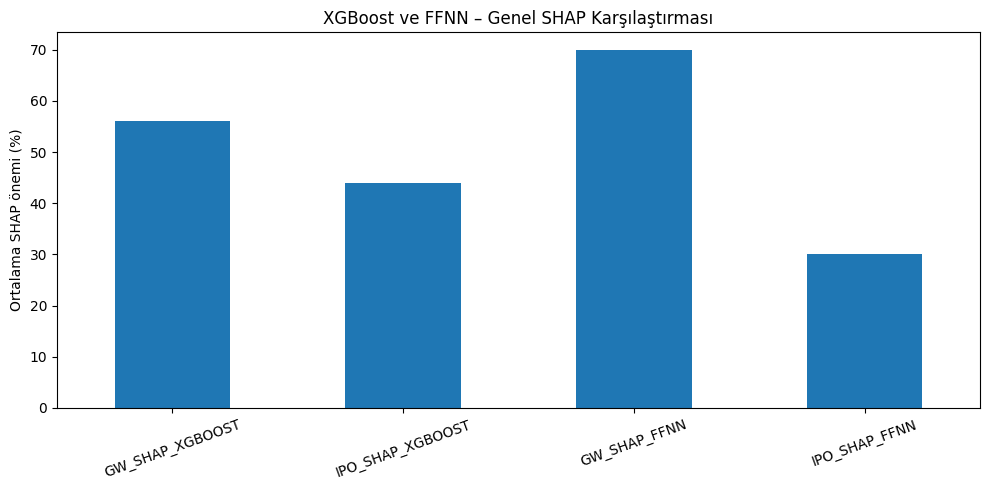

In [36]:
mean_shap = shap_comparison[
    [
        "GW_SHAP_XGBOOST", "IPO_SHAP_XGBOOST",
        "GW_SHAP_FFNN", "IPO_SHAP_FFNN"
    ]
].mean()

plt.figure(figsize=(10, 5))
mean_shap.plot(kind="bar", rot=20)

plt.ylabel("Ortalama SHAP önemi (%)")
plt.title("XGBoost ve FFNN – Genel SHAP Karşılaştırması")
plt.tight_layout()
plt.show()

SHAP önem oranlarını karşılaştıran ısı haritası

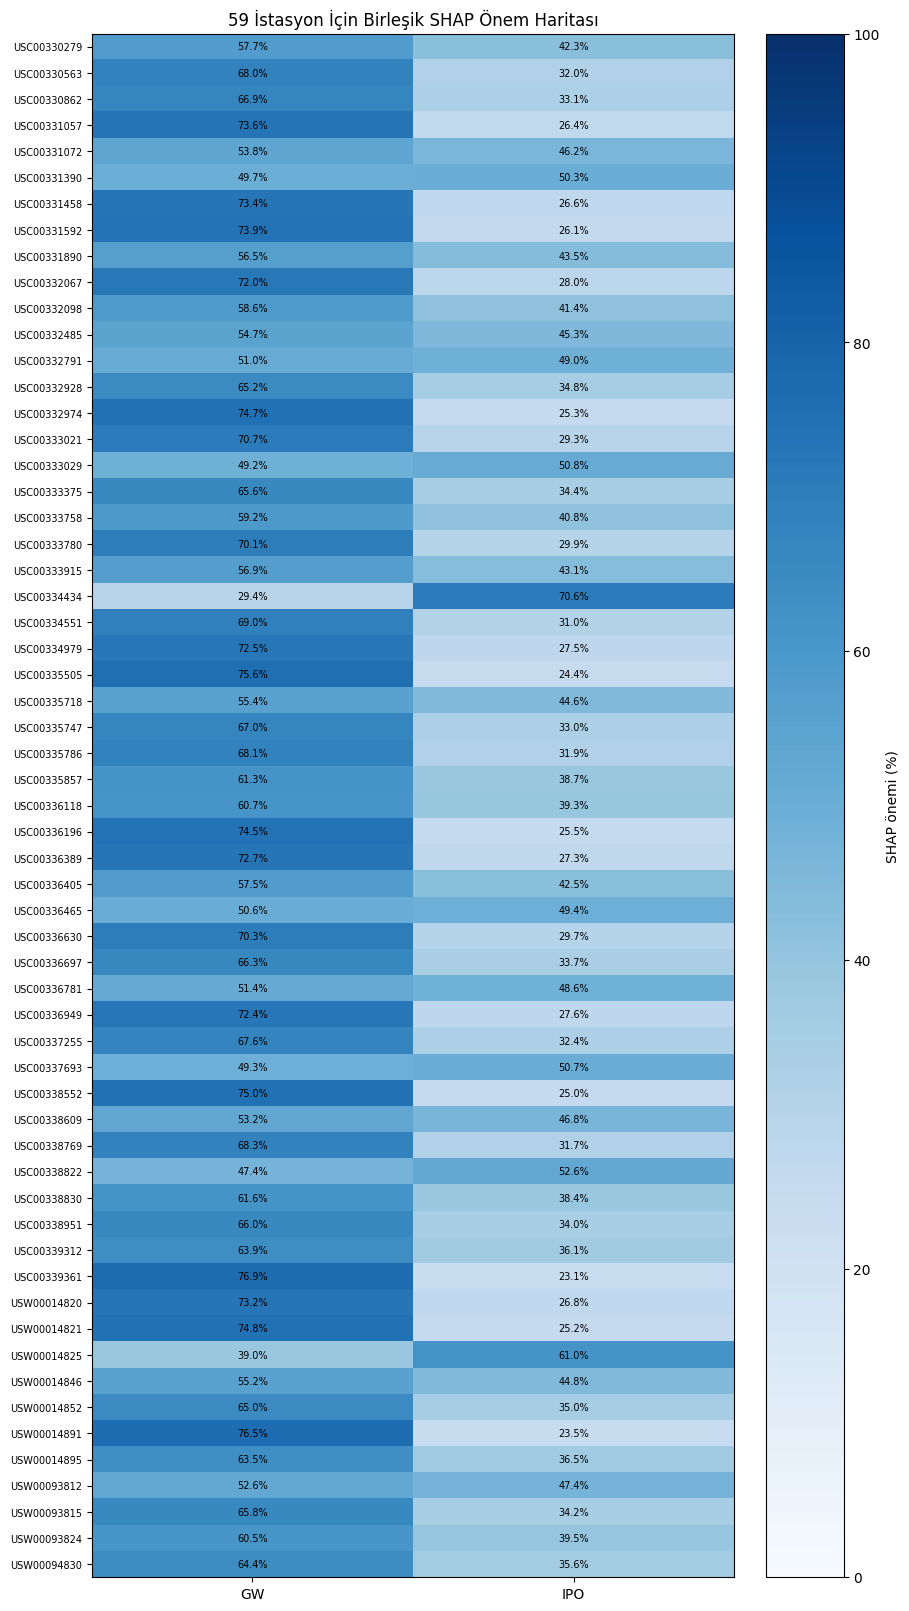

In [39]:
heatmap_data = shap_comparison.set_index("STATION")[
    ["GW_SHAP_MEDIAN", "IPO_SHAP_MEDIAN"]
]

fig, ax = plt.subplots(figsize=(9, 16))

im = ax.imshow(
    heatmap_data.values,
    aspect="auto",
    cmap="Blues",
    vmin=0,
    vmax=100
)

fig.colorbar(im, ax=ax, label="SHAP önemi (%)")

ax.set_xticks([0, 1])
ax.set_xticklabels(["GW", "IPO"])

ax.set_yticks(range(len(heatmap_data)))
ax.set_yticklabels(heatmap_data.index, fontsize=7)

for i in range(len(heatmap_data)):
    for j in range(2):
        value = heatmap_data.iloc[i, j]
        ax.text(
            j, i, f"{value:.1f}%",
            ha="center",
            va="center",
            color="black",
            fontsize=7
        )

ax.set_title("59 İstasyon İçin Birleşik SHAP Önem Haritası")

fig.subplots_adjust(left=0.25, right=0.90, top=0.95, bottom=0.05)
plt.show()

22. hücre – XGBoost SHAP özeti

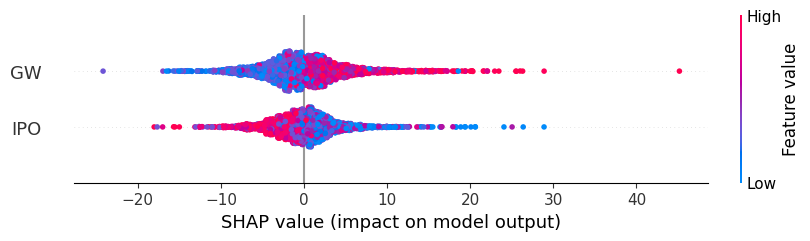

In [47]:
plt.close("all")

fig, ax = plt.subplots(figsize=(9, 5))

shap.plots.beeswarm(
    shap.Explanation(
        values=all_xgb_shap,
        data=all_xgb_features,
        feature_names=FEATURES
    ),
    show=False
)

plt.show()

23. hücre – FFNN SHAP önem grafiği

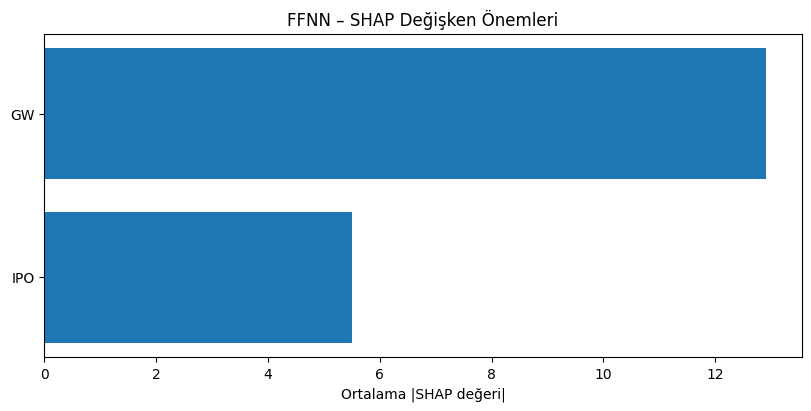

In [44]:
plt.close("all")

all_ffnn_shap = []
all_ffnn_features = []

for station in ffnn_shap_values:
    X_station = model_data[
        model_data["STATION"] == station
    ][FEATURES].values

    all_ffnn_shap.append(ffnn_shap_values[station])
    all_ffnn_features.append(X_station)

all_ffnn_shap = np.vstack(all_ffnn_shap)
all_ffnn_features = np.vstack(all_ffnn_features)

mean_abs_ffnn_shap = np.abs(all_ffnn_shap).mean(axis=0)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(FEATURES, mean_abs_ffnn_shap)

ax.set_xlabel("Ortalama |SHAP değeri|")
ax.set_title("FFNN – SHAP Değişken Önemleri")
ax.invert_yaxis()

plt.show()

24. hücre – PDP grafiği

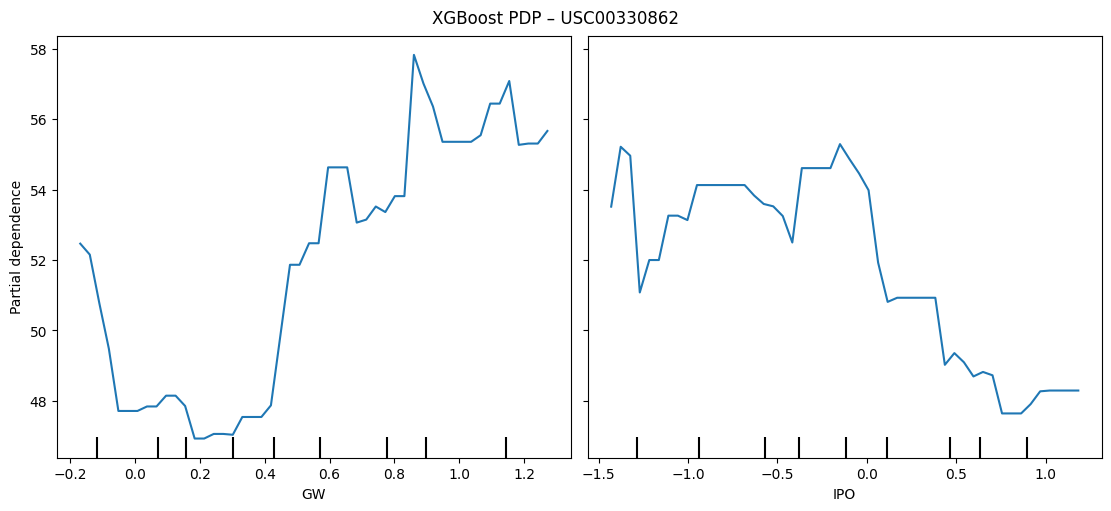

Temsilî istasyon: USC00330862


In [45]:
from sklearn.inspection import PartialDependenceDisplay

representative_station = station_counts.sort_values(
    "count", ascending=False
).iloc[0]["STATION"]

representative_data = model_data[
    model_data["STATION"] == representative_station
]

representative_model = station_full_models[representative_station]

fig, ax = plt.subplots(figsize=(11, 5))

PartialDependenceDisplay.from_estimator(
    representative_model,
    representative_data[FEATURES],
    features=FEATURES,
    grid_resolution=50,
    ax=ax
)

plt.suptitle(f"XGBoost PDP – {representative_station}")
plt.show()

print("Temsilî istasyon:", representative_station)